# Model monitoring - credit default (30dpd_6mob)

For one **as-of date**, builds a month-by-month view of every application month a model scored.
All logic lives in `utils/model_monitoring.py`; `model_monitoring.py` is the same thing as a CLI (used by Airflow):

```
python model_monitoring.py --snapshotdate 2025-07-01
```

| check | available | metric | AMBER | RED |
|---|---|---|---|---|
| score stability | as soon as a month is scored | PSI of scores vs training baseline (held-out test split) | > 0.10 | > 0.25 |
| feature stability | as soon as a month is scored | largest PSI over the model's input features | > 0.10 | > 0.25 |
| performance | once labels mature (application + 6 mob) **and** are known at the as-of date | Gini vs the model's OOT Gini | drop > 10% | drop > 20% |

Each month is also tagged with its **period** relative to the model's own development data:
`train_test` / `oot` (seen during development - performance there is optimistic) or `post_training` (true out-of-time).

In [1]:
import os
import glob
import importlib
import pickle
import pprint
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import pyspark
import pyspark.sql.functions as F
from pyspark.sql.functions import col

import utils.model_monitoring as mm
importlib.reload(mm)

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)

## set up pyspark session

In [2]:
spark = pyspark.sql.SparkSession.builder \
    .appName("model_monitoring") \
    .master("local[*]") \
    .getOrCreate()

spark.sparkContext.setLogLevel("ERROR")

## set up config

In [3]:
as_of_date_str = "2025-07-01"          # labels known up to this date are used
model_name = "credit_model_2024_09_01.pkl"

config = {}
config["as_of_date_str"] = as_of_date_str
config["as_of_date"] = datetime.strptime(as_of_date_str, "%Y-%m-%d")
config["model_name"] = model_name
config["model_version"] = model_name[:-4]
config["model_artefact_filepath"] = mm.MODEL_BANK_DIR + model_name
config["predictions_directory"] = mm.PREDICTIONS_DIR + config["model_version"] + "/"
pprint.pprint(config)

{'as_of_date': datetime.datetime(2025, 7, 1, 0, 0),
 'as_of_date_str': '2025-07-01',
 'model_artefact_filepath': 'model_bank/credit_model_2024_09_01.pkl',
 'model_name': 'credit_model_2024_09_01.pkl',
 'model_version': 'credit_model_2024_09_01',
 'predictions_directory': 'datamart/gold/model_predictions/credit_model_2024_09_01/'}


## load model artefact and its monitoring baseline

In [4]:
with open(config["model_artefact_filepath"], "rb") as f:
    model_artefact = pickle.load(f)

dd = model_artefact["data_dates"]
print("model_version:", model_artefact["model_version"], "| type:", model_artefact["model_type"])
print("train/test labels:", dd["train_test_start_date"].date(), "->", dd["train_test_end_date"].date())
print("OOT labels:       ", dd["oot_start_date"].date(), "->", dd["oot_end_date"].date())
print("reference (OOT) Gini:", model_artefact["results"]["gini_oot"])

baseline = model_artefact["baseline"]
print("\nbaseline: held-out test split,", baseline["n_rows"], "rows,", len(baseline["features"]), "features")
print("score decile edges:", [round(e, 3) for e in baseline["score"]["edges"]])

model_version: credit_model_2024_09_01 | type: xgboost
train/test labels: 2023-07-01 -> 2024-06-30
OOT labels:        2024-07-01 -> 2024-08-31
reference (OOT) Gini: 0.667

baseline: held-out test split, 1192 rows, 57 features
score decile edges: [0.086, 0.138, 0.179, 0.231, 0.287, 0.378, 0.503, 0.685, 0.806]


## which months have predictions?

In [5]:
pred_files = sorted(glob.glob(config["predictions_directory"] + "*.parquet"))
print(len(pred_files), "scored months for", config["model_version"])
print([os.path.basename(f)[-18:-8] for f in pred_files])

23 scored months for credit_model_2024_09_01
['2023_01_01', '2023_02_01', '2023_03_01', '2023_04_01', '2023_05_01', '2023_06_01', '2023_07_01', '2023_08_01', '2023_09_01', '2023_10_01', '2023_11_01', '2023_12_01', '2024_01_01', '2024_02_01', '2024_03_01', '2024_04_01', '2024_05_01', '2024_06_01', '2024_09_01', '2024_10_01', '2024_11_01', '2024_12_01', '2025_01_01']


## load predictions + features + labels known at the as-of date
Predictions are joined to the features they were scored on (for drift) and to labels on
`label.loan_start_date == prediction.snapshot_date` - only labels whose label `snapshot_date` <= as-of date.

In [6]:
data_pdf = mm.load_monitoring_inputs(spark, config["model_version"], config["as_of_date"], model_artefact["feature_cols"])
print(data_pdf.shape, "| labelled:", data_pdf["label"].notna().sum())
data_pdf[["Customer_ID", "snapshot_date", "model_predictions", "label"]].head()

(11452, 62) | labelled: 11452


,Customer_ID,snapshot_date,model_predictions,label
0,CUS_0x1009,2025-01-01,0.260525,0
1,CUS_0x1098,2025-01-01,0.645272,1
2,CUS_0x109f,2025-01-01,0.205377,0
3,CUS_0x10b6,2025-01-01,0.230068,0
4,CUS_0x10e2,2025-01-01,0.608622,0


## compute monitoring table

In [7]:
mon_pdf = mm.monitor_model(data_pdf, model_artefact, config["as_of_date"])
mon_pdf[["snapshot_date", "period", "n_scored", "avg_score", "clickstream_missing", "score_psi",
         "max_feature_psi", "max_psi_feature", "n_labelled", "bad_rate", "gini",
         "status_score_psi", "status_feature_psi", "status_gini", "status"]].round(3)

,snapshot_date,period,n_scored,avg_score,clickstream_missing,score_psi,max_feature_psi,max_psi_feature,n_labelled,bad_rate,gini,status_score_psi,status_feature_psi,status_gini,status
0,2023-01-01,train_test,530,0.358,0.0,0.067,0.059,Num_of_Loan,530,0.264,0.940,GREEN,GREEN,GREEN,GREEN
1,2023-02-01,train_test,501,0.389,0.0,0.089,0.074,Annual_Income,501,0.307,0.887,GREEN,GREEN,GREEN,GREEN
2,2023-03-01,train_test,506,0.405,0.0,0.095,0.064,fe_9,506,0.320,0.904,GREEN,GREEN,GREEN,GREEN
3,2023-04-01,train_test,510,0.370,0.0,0.070,0.054,emi_to_income,510,0.269,0.885,GREEN,GREEN,GREEN,GREEN
4,2023-05-01,train_test,521,0.380,0.0,0.060,0.047,fe_13,521,0.267,0.932,GREEN,GREEN,GREEN,GREEN
5,2023-06-01,train_test,517,0.347,0.0,0.096,0.047,fe_7,517,0.265,0.908,GREEN,GREEN,GREEN,GREEN
6,2023-07-01,train_test,471,0.397,0.0,0.064,0.060,Num_of_Delayed_Payment,471,0.297,0.895,GREEN,GREEN,GREEN,GREEN
7,2023-08-01,train_test,481,0.382,0.0,0.084,0.073,fe_13,481,0.289,0.916,GREEN,GREEN,GREEN,GREEN
8,2023-09-01,train_test,454,0.366,0.0,0.068,0.069,Annual_Income,454,0.262,0.908,GREEN,GREEN,GREEN,GREEN
9,2023-10-01,train_test,487,0.365,0.0,0.080,0.043,Num_Credit_Inquiries,487,0.257,0.933,GREEN,GREEN,GREEN,GREEN


## monitoring charts
Shaded months were seen during development (train/test + OOT).

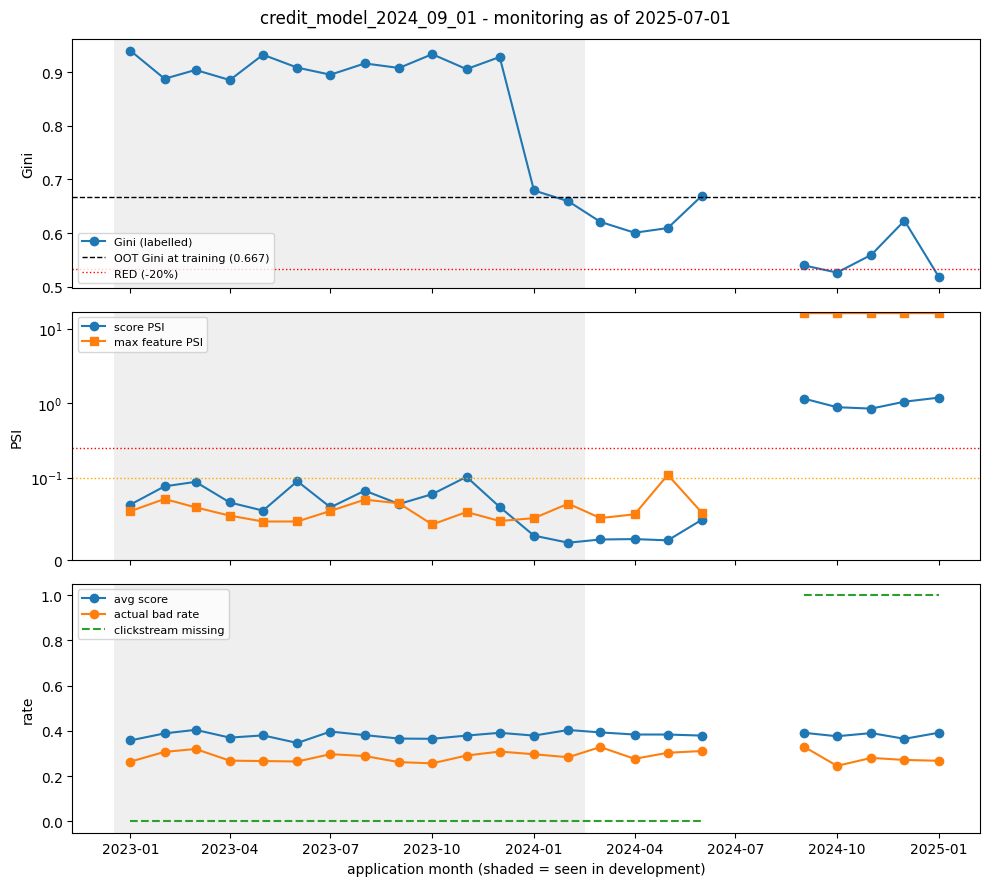

In [8]:
fig = mm.plot_monitoring(mon_pdf)
plt.show()

## summary by period

In [9]:
mon_pdf.groupby("period", sort=False).agg(
    months=("snapshot_date", "count"),
    avg_gini=("gini", "mean"),
    avg_score_psi=("score_psi", "mean"),
    avg_clickstream_missing=("clickstream_missing", "mean"),
    red_months=("status", lambda s: (s == "RED").sum()),
).round(3)

,months,avg_gini,avg_score_psi,avg_clickstream_missing,red_months
period,,,,,
train_test,12,0.912,0.078,0.000,0
oot,2,0.669,0.026,0.000,0
post_training,9,0.585,0.581,0.556,5


## feature drift in the latest scored month
Top features by PSI vs the training baseline.

In [10]:
latest_month = data_pdf["snapshot_date"].max()
latest = data_pdf[data_pdf["snapshot_date"] == latest_month]
f_psi = pd.Series(mm.feature_psis(baseline, latest)).sort_values(ascending=False)
print("latest scored month:", latest_month.date())
f_psi.head(10).round(3).to_frame("psi").assign(status=lambda d: d["psi"].map(mm.psi_status))

latest scored month: 2025-01-01


,psi,status
fe_15,16.111,RED
fe_4,16.111,RED
fe_5,16.111,RED
fe_16,16.111,RED
fe_11,16.111,RED
fe_20,16.111,RED
fe_19,16.111,RED
fe_8,16.111,RED
fe_18,16.111,RED
fe_2,16.111,RED


### reading the result
* **Clickstream gap** - from application month 2024-07 the clickstream feed has no rows for applicants, so every `fe_*`
  is null. The model never saw a missing clickstream in training, so feature PSI explodes and the score distribution shifts.
* **Performance** - once those months' labels mature, Gini drops below the RED line (-20% vs the OOT Gini).
* **Action** - retrain on data that contains missing clickstream (see `credit_model_2025_04_01` in `model_train_main.ipynb`)
  or fix the clickstream feed.

## save monitoring to datamart gold table

In [11]:
filepath, chart_path = mm.save_monitoring(spark, mon_pdf)

saved to: datamart/gold/model_monitoring/credit_model_2024_09_01/credit_model_2024_09_01_monitoring_2025_07_01.parquet


chart saved to: datamart/gold/model_monitoring/credit_model_2024_09_01/credit_model_2024_09_01_monitoring_2025_07_01.png


## monitor all models (what the Airflow task runs)

In [12]:
results = mm.run_monitoring(spark, config["as_of_date_str"])

saved to: datamart/gold/model_monitoring/credit_model_2024_09_01/credit_model_2024_09_01_monitoring_2025_07_01.parquet


chart saved to: datamart/gold/model_monitoring/credit_model_2024_09_01/credit_model_2024_09_01_monitoring_2025_07_01.png
credit_model_2024_09_01: 23 months | latest scored month 2025-01-01 status=RED (score_psi=1.184, max_feature_psi=16.111 [fe_15])
   latest post-training Gini: 0.519 for 2025-01-01 vs reference 0.667 -> RED


saved to: datamart/gold/model_monitoring/credit_model_2025_04_01/credit_model_2025_04_01_monitoring_2025_07_01.parquet


chart saved to: datamart/gold/model_monitoring/credit_model_2025_04_01/credit_model_2025_04_01_monitoring_2025_07_01.png
credit_model_2025_04_01: 1 months | latest scored month 2024-09-01 status=RED (score_psi=0.083, max_feature_psi=8.574 [fe_9])


## check datamart

In [13]:
folder_path = mm.MONITORING_DIR + config["model_version"] + "/"
files_list = sorted(glob.glob(folder_path + "*.parquet"))
print([os.path.basename(f) for f in files_list])

df = spark.read.parquet(files_list[-1])
print("row_count:", df.count())
df.select("snapshot_date", "period", "score_psi", "max_feature_psi", "gini", "status").orderBy("snapshot_date").show(30)

['credit_model_2024_09_01_monitoring_2025_07_01.parquet']


row_count: 23


+-------------+-------------+--------------------+--------------------+------------------+------+
|snapshot_date|       period|           score_psi|     max_feature_psi|              gini|status|
+-------------+-------------+--------------------+--------------------+------------------+------+
|   2023-01-01|   train_test| 0.06736448608538687| 0.05940478547098824|  0.93996336996337| GREEN|
|   2023-02-01|   train_test| 0.08946099981276301| 0.07422372813594055|0.8874583629626855| GREEN|
|   2023-03-01|   train_test| 0.09485921842543955| 0.06406639684847547|0.9038903244329599| GREEN|
|   2023-04-01|   train_test| 0.06996686425120487| 0.05405865273851306|0.8850903113442008| GREEN|
|   2023-05-01|   train_test|0.060130481821664805| 0.04698830777237918|0.9322385023918041| GREEN|
|   2023-06-01|   train_test| 0.09563329681932127| 0.04701006755314056|0.9082212831348444| GREEN|
|   2023-07-01|   train_test| 0.06409544911152237| 0.05977212561889197|0.8950366853690115| GREEN|
|   2023-08-01|   tr